#ML FINAL EXAM

### Email:rayhanc2002@gmail.com

Task: Copy this notebook on your drive and answer in that copy

Choose a dataset of your choice from kaggle or UCI

Some suggestions:https://www.kaggle.com/datasets/ahmettezcantekin/beginner-datasets

You may choose a dataset of your choice too

In this exam:
1. Provide code and explaination(in text cell) whenever needed and you must show the outputs
2. Before submitting run all cells and make sure the outputs are visible


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder,StandardScaler,MinMaxScaler,RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split



from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import r2_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.model_selection import GridSearchCV

In [2]:
df = pd.read_csv('/content/bank.csv')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
df.shape

(11162, 17)

In [4]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


## 0. Dataset overview

Why you choose this dataset and what did you observe from the dataset description



  

## Answer:
I choose this dataset beacuse it is a classification data and it contains both numerical and catagorical feature , making it suitable for Data preprocession , EDA And modeling.In the dataset there is 11162 rows and 17 columns.



# 1. Dataset description (15 marks)


### Dataset Description
1.How many features? -->There are 17 Numerical and categorical mix feature

2.Classification or regression problem Why do you think so?--> Classification problem beacuse the target is deposit.

3.How many data points? --> 11,162

4.Is there any null values? --> No,There is no Null value in this dataset

5.What kind of features are in your dataset? (Quantitative / Categorical) --> Both Mix there are Total 17 Feature in the dataset and 10 Catagorical and 7 Numerical Features

6.Do you need to encode the categorical variables, why or why not? --> Yes it will need to be encoded because ML models only understand numbers, not text ('job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit', dtype='object). So these need to be converted to numeric using OneHotEncoder/OrdinalEncoder.

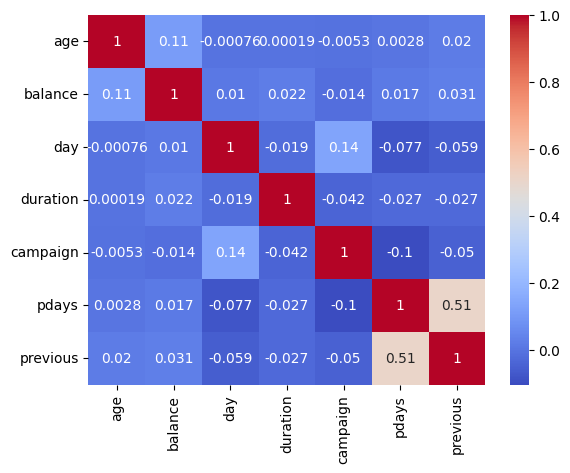

In [7]:
# 7.Correlation
num_com = (['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'])
sns.heatmap(df[num_com].corr(), annot=True, cmap="coolwarm")
plt.show()


Most numerical features show almost zero linear relationship with each other, meaning they are independent.There is a moderate positive correlation (0.51) between pdays and previous.

##Answer:





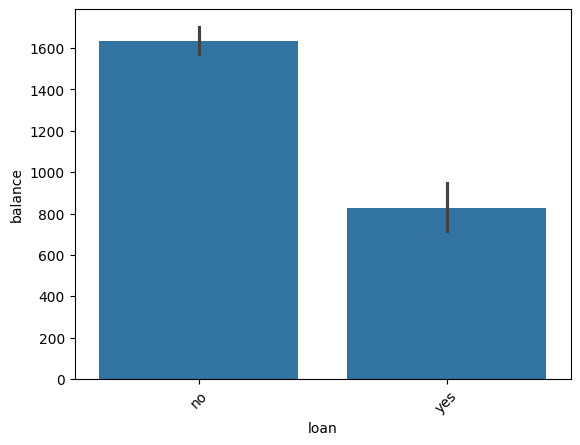

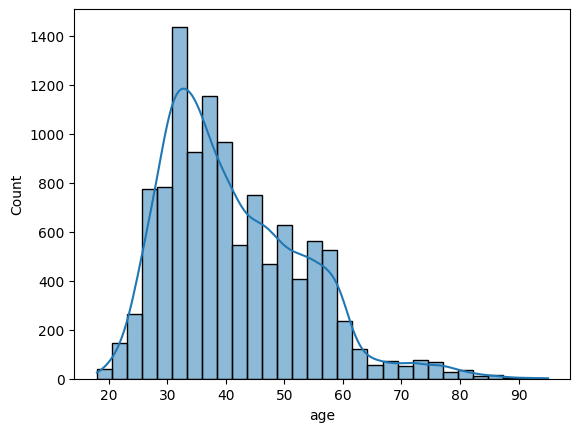

In [8]:
#8.Perform exploratory data analysis to extract some important relationships from your data.
#Loan vs Balance
sns.barplot(data=df, x='loan', y = 'balance')
plt.xticks(rotation=45)
plt.show()


# Age
sns.histplot(df['age'], bins=30, kde=True)
plt.show()

The bar plot indicates that individuals without a personal loan maintain a significantly higher average account balance compared to those who have a loan. Meanwhile, the age distribution histogram shows that the dataset is right-skewed, peaking heavily around the early 30s. The majority of individuals fall between the ages of 25 and 60, with a sharp drop-off in population representation past age 60. Together these visualizations suggest that financial stability varies by loan status and that the target demographic heavily skews toward younger working-age individuals.

#2. Dataset pre-processing (15 marks)

1. Provide code
2. Discuss the pre processing steps you applied and why?


In [18]:
categories = [['unknown', 'primary', 'secondary', 'tertiary']]

# pipelines
p1 = Pipeline(
    steps=[
        ('scaling', StandardScaler())
        ]) # age

p2 = Pipeline(
    steps=[('scaler', MinMaxScaler())
    ])

p3 = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'))
    ]
)
p4 = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=categories)),
        ('scaler', MinMaxScaler())
    ]
)
p5 = Pipeline(
    steps=[
        ('scaler', RobustScaler())
        ])

# column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('pipeline_1', p1, ['age']),
        ('pipeline_2', p2, ['day', 'campaign', 'previous', 'pdays']),
        ('pipeline_3', p3, ['job', 'marital', 'contact', 'month', 'poutcome', 'default', 'housing', 'loan']),
        ('pipeline_4', p4, ['education']),
        ('pipeline_5', p5, ['balance']),
    ],
    remainder='passthrough'
)

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('pipeline_1',
                                 Pipeline(steps=[('scaling',
                                                  StandardScaler())]),
                                 ['age']),
                                ('pipeline_2',
                                 Pipeline(steps=[('scaler', MinMaxScaler())]),
                                 ['day', 'campaign', 'previous', 'pdays']),
                                ('pipeline_3',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_...
                                 ['job', 'marital', 'contact', 'month',
                                  'poutcome', 'default', 'housing', 'loan']),
                                ('pipeline_4',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(categories=[['unknown',
                                                                              'primary',
                                                                              'secondary',
                                                                              'tertiary']])),
                                                 ('scaler', MinMaxScaler())]),
                                 ['education']),
                                ('pipeline_5',
                                 Pipeline(steps=[('scaler', RobustScaler())]),
                                 ['balance'])])

#Answer :


> Numeric Features (p1, p2, p5): Standard scaling (StandardScaler) is applied to age to center it around zero, while Min-Max scaling (MinMaxScaler) bounds skewed or discrete counts (day, campaign, previous, pdays) between 0 and 1. RobustScaler is specifically chosen for balance to scale the data using quartiles, preventing extreme outliers from distorting the feature.



> Categorical Features (p3, p4): Missing values in all nominal and ordinal categories are first handled by replacing them with the most frequent value (SimpleImputer). Nominal categories like job and marital are then dummy-encoded using OneHotEncoder (dropping the first column to avoid multi-collinearity), while education is converted to structured numerical ranks using OrdinalEncoder and subsequently normalized to a 0–1 range.





#3.Feature selection and Dataset splitting (10 marks)

1. Which features you wanna keep ? Justify and drop and rest or apply any other feature engineering step
2. Perform Train test split

In [10]:
X = df.drop(['duration', 'deposit'], axis=1)
y = df['deposit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Answer:
building a ml pipeline to predict if a customer will subscribe to a term deposit . keeping all features except deposit and duration (dropped to prevent data leakage).Target is,  y = df['deposit'] and lastly split into an 80% training set (X_train, y_train) and a 20% testing set (X_test, y_test).


#4.  Pipeline Creation (Supervised) (10 marks)

Select 2 models of your choice and build 2 pipelines for them

## Answer:

In [11]:
lr_model = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('Model', LogisticRegression())
    ]
)
lr_model

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline_1',
                                                  Pipeline(steps=[('scaling',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('pipeline_2',
                                                  Pipeline(steps=[('scaler',
                                                                   MinMaxScaler())]),
                                                  ['day', 'campaign',
                                                   'previous', 'pdays']),
                                                 ('pipeline_3',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   O...
                                                   'month', 'poutcome',
                                                   'default', 'housing',
                                                   'loan']),
                                                 ('pipeline_4',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(categories=[['unknown',
                                                                                               'primary',
                                                                                               'secondary',
                                                                                               'tertiary']])),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['education']),
                                                 ('pipeline_5',
                                                  Pipeline(steps=[('scaler',
                                                                   RobustScaler())]),
                                                  ['balance'])])),
                ('Model', LogisticRegression())])

In [12]:
#Random Forest

rf_model = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('Model', RandomForestClassifier())
    ]
)

grid_param = {
    "Model__n_estimators": [100, 150, 200, 300, 400],
    "Model__criterion": ['gini', 'entropy'],
    "Model__max_features": ['sqrt', 'log2'],
}

grid_search_RF = GridSearchCV(estimator=rf_model, param_grid=grid_param, cv=5)
grid_search_RF.fit(X_train, y_train)

y_pred_train = grid_search_RF.predict(X_train)
y_pred_test  = grid_search_RF.predict(X_test)


# 5. Model Training (5 marks)

Train those 2 models



## Answer:

In [13]:
# Logistic Regression
lr_model.fit(X_train,y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline_1',
                                                  Pipeline(steps=[('scaling',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('pipeline_2',
                                                  Pipeline(steps=[('scaler',
                                                                   MinMaxScaler())]),
                                                  ['day', 'campaign',
                                                   'previous', 'pdays']),
                                                 ('pipeline_3',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   O...
                                                   'month', 'poutcome',
                                                   'default', 'housing',
                                                   'loan']),
                                                 ('pipeline_4',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(categories=[['unknown',
                                                                                               'primary',
                                                                                               'secondary',
                                                                                               'tertiary']])),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['education']),
                                                 ('pipeline_5',
                                                  Pipeline(steps=[('scaler',
                                                                   RobustScaler())]),
                                                  ['balance'])])),
                ('Model', LogisticRegression())])

#6. Model selection/Comparison analysis (15 marks)
* Bar chart showcasing prediction accuracy of all models (for classification)
* Precision, recall comparison of each model. (for classification)
* Confusion Matrix (for classification)
* R2 score and Loss  (for regression)

Compare the results of all models based on all of the above described metrics. Why do you think this model performed better than the other one for this dataset?

# Answer:

In [14]:
# Logistic
y_pred_lr = lr_model.predict(X_test)

Accuracy = accuracy_score(y_test, y_pred_lr)
print("Accuracy Score :",Accuracy)

precision = precision_score(y_test,y_pred_lr,pos_label='yes')
print("Precision Score : ",precision)


recall = recall_score(y_test,y_pred_lr,pos_label='yes')
print("Recall Score : ",recall)

Accuracy Score : 0.7138378862516793
Precision Score :  0.7708860759493671
Recall Score :  0.5707591377694471


In [15]:
# Random Forest
y_pred_rf = grid_search_RF.predict(X_test)

precision_rf = precision_score(y_test, y_pred_rf, pos_label='yes')
print('precision for Random Forest :',precision_rf)

recall_rf    = recall_score(y_test, y_pred_rf, pos_label='yes')
print('Recall for Random Forest :',recall_rf)

cm = confusion_matrix(y_test,y_pred_rf)
print("Confusion Matrix : \n",cm)

precision for Random Forest : 0.7619047619047619
Recall for Random Forest : 0.6447985004686035
Confusion Matrix : 
 [[951 215]
 [379 688]]


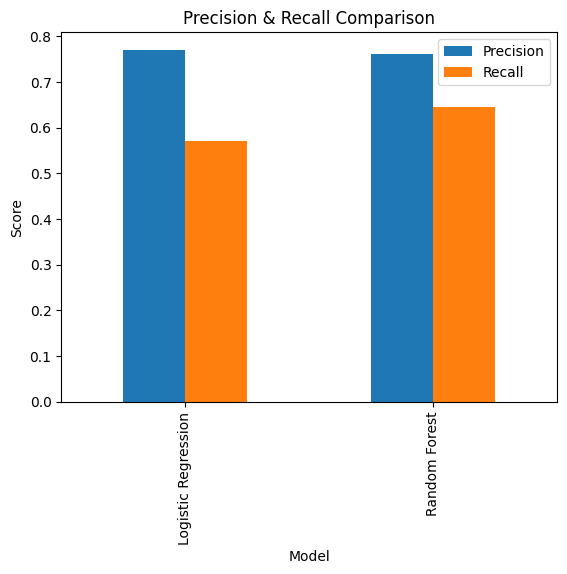

In [16]:
#Bar chart using 2 model
metrics_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Precision': [precision, precision_rf],
    'Recall': [recall, recall_rf]
})
metrics_df.plot(x='Model', y=['Precision', 'Recall'], kind='bar')
plt.title("Precision & Recall Comparison")
plt.ylabel("Score")
plt.show()

> Precision: Both Logistic Regression and Random Forest perform almost equally well, achieving a high precision score of approximately 0.77.

> Recall: Random Forest noticeably outperforms Logistic Regression, achieving a score around 0.65 compared to Logistic Regression's score of roughly 0.57.

 Random Forest is the better overall model here because it maintains the same precision while capturing significantly more true positive cases (higher recall).

# 7. Treating the problem as Unsupervised (20 marks) ( Explore the topic as you wish )

1. Treat the problem as a unsupervised problem and perform any unsupervised model and evalute the result
2. Which method worked better? supervised or unsupervised approach and why?

# Answer:

In [17]:
X_unsup = df.drop(['duration', 'deposit'], axis=1)
y_true  = df['deposit']

#8. Self Reflection on this machine learning course (10 marks)

Explain the hardest and the easiest topic of this course according to you in a intuitive way (you may also provide real world implementation , necessity etc along with the explaination)

##Answer:



> Honestly speaking This course is very good , as a biginer i learn a lots of intersting thing from this course . and thanks to Mr Adil who use to explain every details of every topic , as my prospectus i really feel hard about Logistic regression when i am practicing step by step and after with sklean it beacome easy . i face a problem about video dureation . and talking about real world implementation those model i learn form phitron  



---



> Linear & Logistic Regression (Supervised Learning)

Linear Regression predicts a continuous number (like a line on a graph).

Logistic Regression classifies things into groups (Yes/No, Spam/Not Spam).



---



> K-Means Clustering (Unsupervised Learning)
Another highly intuitive topic. It groups unlabeled data into clusters based on how close or similar the data points are to each other.

Real-World Implementation & Necessity:
Customer Segmentation: E-commerce platforms like Amazon or Netflix use K-Means to group users based on their buying habits, age, and browsing history.

Image Compression: It can group similar pixel colors together to reduce the file size of an image without losing much quality.




---



> Decision Trees & Random Forests:

to understand they look like flowcharts ("If income > $50k, go left; else, go right"), but optimizing them and avoiding overfitting can get tricky.

Real-World Implementation & Necessity
Medical: Doctors and hospitals use decision tree based models to diagnose diseases. By entering symptoms (Fever: Yes/No, Blood Pressure: High/Low)

E-commerce Fraud Detection: Payment gateways use Random Forests to instantly analyze if a transaction is fraudulent based on location, transaction size, and time of day.







